In [ ]:
from __future__ import absolute_import, division, print_function, unicode_literals

import warnings

warnings.simplefilter("ignore")

# general purpose packages
import pandas as pd
import numpy as np
import os
import json
import time
import re
import csv
import subprocess
import sys

from dotenv import load_dotenv
from pathlib import Path

import scipy.stats as stats
import statsmodels.stats as smstats
from statsmodels.stats.multitest import multipletests

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import sklearn

from multiprocessing import Process, Manager, Pool
import multiprocessing
from functools import partial

from collections import Counter

import seaborn as sns

sns.set()

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

matplotlib.rcParams["backend"] = "Qt5Agg"
import matplotlib.ticker as ticker
from matplotlib.ticker import FuncFormatter

from IPython.display import display, Image

from adjustText import adjust_text
import builtins

%matplotlib inline

# for working with sam/bam files
import HTSeq

# for working with fasta files for example
from Bio import SeqIO

# for working with yaml files
import ruamel.yaml

import itertools

In [ ]:
def get_pvalue_star(pval, thr=0.05):
    if thr == 0.05:
        if pval < 0.001:
            return "***"
        elif pval < 0.01:
            return "**"
        elif pval < 0.05:
            return "*"
        else:
            return "ns"
    elif thr == 0.1:
        if pval < 0.001:
            return "***"
        elif pval < 0.01:
            return "**"
        elif pval < 0.1:
            return "*"
        else:
            return "ns"

In [ ]:
# 1. Load the environment variables
load_dotenv("CRISPR_projects.scicore.env")

# 2. Reconstruct the subdirs dictionary
subdirs = {
    "lab_group_dir": os.getenv("LAB_GROUP_DIR"),
    "main_project_dir": os.getenv("MAIN_PROJECT_DIR"),
    "wf_dir": os.getenv("WF_DIR"),
    "UCSCtracks_dir": os.getenv("UCSC_TRACKS_DIR"),
    "UCSCtracks_trackfiles_dir": os.getenv("UCSC_TRACKFILES_DIR"),
    "UCSCtracks_trackhubs_dir": os.getenv("UCSC_TRACKHUBS_DIR"),
    "human_annotation_dir": os.getenv("HUMAN_ANNOTATION_DIR"),
    "shared_project_dir": os.getenv("SHARED_PROJECT_DIR"),
    "temp_dir": os.getenv("TEMP_DIR"),
    "slurm_dir": os.getenv("SLURM_DIR"),
    "slurm_scripts_dir": os.getenv("SLURM_SCRIPTS_DIR"),
    "figures_dir": os.getenv("FIGURES_DIR"),
    "tables_dir": os.getenv("TABLES_DIR"),
    "fastq_dir": os.getenv("FASTQ_DIR"),
    "metadata_dir": os.getenv("METADATA_DIR"),
    "ext_data_dir": os.getenv("EXT_DATA_DIR"),
    "wf_runs_dir": os.getenv("WF_RUNS_DIR"),
    "HCC_nORFs_dir": os.getenv("HCC_NORFS_DIR"), # specific for HCC translation project, made by Dr. Meric Ataman
}

# 3. Reconstruct the file_paths dictionary
file_paths = {
    "human_genome_file": os.getenv("HUMAN_GENOME_FILE"),
    "human_chrom_sizes_file": os.getenv("HUMAN_CHROM_SIZES_FILE"),
    "human_annotation_file": os.getenv("HUMAN_ANNOTATION_FILE"),
    "human_basic_annotation_file": os.getenv("HUMAN_BASIC_ANNOTATION_FILE"),
    "human_RNAcentral_annotation_file": os.getenv("HUMAN_RNACENTRAL_ANNOTATION_FILE"),
    "human_enriched_annotation_file": os.getenv("HUMAN_ENRICHED_ANNOTATION_FILE"),
    "human_RefSeq_annotation_file": os.getenv("HUMAN_REFSEQ_ANNOTATION_FILE"),
    "human_RefSeq_chrNames": os.getenv("HUMAN_REFSEQ_CHRNAMES"),
    "human_PRErRNA_file": os.getenv("HUMAN_PRERRNA_FILE"),
    "human_polyAsite_atlas": os.getenv("HUMAN_POLYASITE_ATLAS"),
    "human_tandem_PAS": os.getenv("HUMAN_TANDEM_PAS"),
    "lincRNA_annotation_file": os.getenv("LINCRNA_ANNOTATION_FILE"), # specific for HCC translation project, used by Dr. Meric Ataman
    "lincRNA_ORFs": os.getenv("LINCRNA_ORFS"), # specific for HCC translation project, used by Dr. Meric Ataman
    "ORFs_main_annotation_file": os.getenv("ORFS_MAIN_ANNOTATION_FILE"), # specific for HCC translation project, used by Dr. Meric Ataman
}

# 4. Safely create all subdirectories
# Using os.makedirs is highly preferred over os.system('mkdir -p')
# because it avoids opening a subshell and handles permissions gracefully in pure Python.
for path in subdirs.values():
    if path:  # Safety check to ensure the variable was actually found in the .env
        os.makedirs(path, exist_ok=True)

print("Environment loaded and directories verified.")

# Analyzing evolutionary and population genetics features of nORFs vs CDSs related to liver

## Prepare bed-formatted file with all transcript coordinates of analyzed ORFs

In [ ]:
# Prepare combined .bed file with all transcriptomic coordinates of nORFs

In [ ]:
transcript_coords_nORF_files = {
    'uORF':{'RiboSeq_evidence':'uorfs_hcc_genome_coords.bed','no_evidence':'unsuccessful_uORF_coordinates.tsv'},
    'dORF':{'RiboSeq_evidence':'dorfs_hcc_genome_coords.bed','no_evidence':'unsuccessful_dORF_coordinates.tsv'},
    'RT':{'RiboSeq_evidence':'rts_hcc_genome_coords.bed','no_evidence':'unsuccessful_RT_coordinates.tsv'},
    'lincRNA':{'RiboSeq_evidence':None,'no_evidence':'unsuccessful_lncrna_coordinates.txt'},
}

a = []
for category in transcript_coords_nORF_files.keys():
    for file_type in transcript_coords_nORF_files[category].keys():
        if transcript_coords_nORF_files[category][file_type] is not None:
            file_path = os.path.join(subdirs['HCC_nORFs_dir'],transcript_coords_nORF_files[category][file_type])
            tmp_df = pd.read_csv(file_path, sep='\t', header=None) # expect a three-column tab-delimited file without header
            tmp_df.columns = ['transcript_id','start','end']
            tmp_df['transcript_id'] = tmp_df['transcript_id'].str.replace('_','.') # need to reformat to adhere to namings in .gtf file
            tmp_df['nORF_type'] = category
            tmp_df['subset'] = file_type
            a.append(tmp_df)
nORFs_df = pd.concat(a).reset_index(drop=True) # include so far only nORFs in protein-coding transcripts

# identified lincRNA ORFs were collected separately

lincRNA_ORFs_df = pd.read_csv(file_paths['lincRNA_ORFs'], sep='\t', header=None)
lincRNA_ORFs_df[0] = lincRNA_ORFs_df[0].str.replace('_','.') # need to reformat to adhere to namings in .gtf file

lincRNA_ORFs_df.columns = ['transcript_id','start','end']
lincRNA_ORFs_df['nORF_type'] = 'lincRNA'
lincRNA_ORFs_df['subset'] = 'RiboSeq_evidence'

nORFs_df = pd.concat([nORFs_df,lincRNA_ORFs_df]).reset_index(drop=True) # now we have complete set of nORFs

In [ ]:
nORFs_df['t']=1
nORFs_df.groupby(['nORF_type','subset']).agg({'t':sum}).reset_index().sort_values(['nORF_type','subset'])

In [ ]:
# extract CDS transcriptomic coords from the annotation

# Define outdir where to write prepared files
outdir = os.path.join(subdirs['tables_dir'],'HCC_ORFs','annotations')
os.makedirs(outdir, exist_ok=True)

CDS_transcriptomic_coords_path = os.path.join(outdir, 'CDS_transcriptomic_coords.bed') # term .bed for consistency with nORFs

command = "cds_to_transcriptomic"+\
" -g "+file_paths['ORFs_main_annotation_file']+\
" -o "+CDS_transcriptomic_coords_path+\
" --include_stop_codon"
print(command)
# On the computational node in bash, activate `zavolab_pyutils` env and then execute the printed command

In [ ]:
CDSs_df = pd.read_csv(CDS_transcriptomic_coords_path, sep='\t', header=None)

# Select the representative transcript per gene - take transcript_ids from the file prepared by Meric
CDS_sel_transcripts_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'transcript_id_gene_id_CDS.tsv'), index_col=None, header=None,delimiter="\t",)
CDSs_df = CDSs_df.loc[CDSs_df[0].isin(list(CDS_sel_transcripts_df[0].unique()))].reset_index(drop=True)

CDSs_df.columns = ['transcript_id','start','end']

In [ ]:
# Check: show nORF categories that have no matching CDS transcript (should only be lincRNAs)
CDSs_df['CDS_present'] = 1
tmp_df = pd.merge(nORFs_df, CDSs_df[['transcript_id', 'CDS_present']], how='left', on='transcript_id')
tmp_df['t'] = 1
display(tmp_df.loc[tmp_df['CDS_present'].isna()].groupby(['nORF_type', 'subset']).agg({'t': sum}).reset_index())

the displayed table only includes lincRNAs, which is expected. It means that for uORFs, dORFs, RTs, we have all respective CDSs

In [ ]:
CDSs_df['custom_transcript_id'] = CDSs_df['transcript_id']+'_CDS_1'+'_'+CDSs_df['start'].astype('str')+'_'+CDSs_df['end'].astype('str')
subset_dict = {'RiboSeq_evidence':1,'no_evidence':0} # for more efficient storage in text files
nORFs_df['custom_transcript_id'] = nORFs_df['transcript_id']+'_'+nORFs_df['nORF_type']+'_'+nORFs_df['subset'].map(subset_dict).astype('str')+'_'+nORFs_df['start'].astype('str')+'_'+nORFs_df['end'].astype('str')
display(CDSs_df.head())
display(nORFs_df.head())

In [ ]:
transcript_coords_df = pd.concat([
    nORFs_df[['transcript_id', 'start', 'end', 'custom_transcript_id']],
    CDSs_df[['transcript_id', 'start', 'end', 'custom_transcript_id']]
]).reset_index(drop=True)
print(len(transcript_coords_df))

In [ ]:
transcript_coords_bed_path = os.path.join(outdir,'transcript_coords.12_06_26.bed')
transcript_coords_df.to_csv(transcript_coords_bed_path,sep=str('\t'),header=False,index=None,quoting=csv.QUOTE_NONE)

## Make combined .gtf from NONCODE and Ensembl - with genomic coordinates

In [ ]:
# we need to make combined .gtf with both lincRNA and main annotated transcripts from Ensembl

# this is the file that Meric used as a source
gtf = pd.read_csv(file_paths['ORFs_main_annotation_file'],delimiter="\t",index_col=None,header=None,comment='#')
gtf[0] = ('chr'+gtf[0].astype('str')).str.replace('chrMT','chrM') # adhere to GENCODE chromosome names

In [ ]:
lincRNA_gtf = pd.read_csv(file_paths['lincRNA_annotation_file'],delimiter="\t",index_col=None,header=None,comment='#')
lincRNA_gtf = lincRNA_gtf.loc[lincRNA_gtf[0].str.startswith('chr')].reset_index(drop=True) # discard broken lines in this .gtf

In [ ]:
# check that this annotation now has all the transcript ids used in nORFs

lincRNA_gtf['transcript_id'] = lincRNA_gtf[8].str.extract(r'transcript_id "([^"]+)"', expand=False) 

lincRNA_gtf['gtf_present'] = 1
tmp_df = pd.merge(nORFs_df.loc[nORFs_df['nORF_type']=='lincRNA'],
        lincRNA_gtf[['transcript_id','gtf_present']].drop_duplicates(),
         how='left',on = ['transcript_id'])
print(f'{len(tmp_df.loc[tmp_df['gtf_present']!=1])} lincRNA from ORF set dont have respective annotation')

In [ ]:
lincRNA_gtf = lincRNA_gtf.drop(['transcript_id','gtf_present'],axis=1) # not needed further

In [ ]:
gtf_df_compiled = pd.concat([gtf,lincRNA_gtf]).reset_index(drop=True) # appended lincRNA and main annotation

In [ ]:
gtf_df_compiled = gtf_df_compiled.sort_values([0,3]).reset_index(drop=True) # make it directly IGV-compatible

In [ ]:
gtf_df_compiled.to_csv(os.path.join(outdir, 'compiled_genome_annotation.gtf'), sep=str('\t'),header=False,index=None,quoting=csv.QUOTE_NONE)

## Transform transcriptomic coordinates of ORFs to genomic coordinates

In [ ]:
nORFs_CDSs_gtf_path = os.path.join(outdir,'nORFs_CDSs.gtf') # this will be output

input_gtf_path = os.path.join(outdir, 'compiled_genome_annotation.gtf')

command = "transcript_to_genomic"+\
" -b "+transcript_coords_bed_path+\
" -g "+input_gtf_path+\
" -o "+nORFs_CDSs_gtf_path+\
" -t $SCRATCH"
print(command)
# On the computational node in bash, activate `zavolab_pyutils` env and then execute the printed command

In [ ]:
print(f'transcript_to_genomic should have converted {len(transcript_coords_df)} nORFs and CDSs to genomic coordinates')

In [ ]:
# load the prepared .gtf file with proper chromosome names (see above)
from zavolab_pyutils.general import (
    parse_gtf_attributes_into_pd_dataframes,
)

gtf_df, genes_df, exons_df = parse_gtf_attributes_into_pd_dataframes(nORFs_CDSs_gtf_path,
                                                                     gene_type_field = "gene_type",
                                                                     extract_exon_number = True, 
                                                                     extract_gene_name_in_exons = True,
                                                                     verbose=False,
                                                                    )

87 lincRNAs from input .bed file could not make genomic coordinates, because the **STRAND** information in the NONCODE .gtf file was lacking for them (column 6 was "." instead of "+" or "-")

In [ ]:
transcript_coords_df.loc[~transcript_coords_df['custom_transcript_id'].isin(list(exons_df['transcript_id'].unique()))]

In [ ]:
lincRNA_gtf.loc[lincRNA_gtf[8].str.contains('NONHSAT154152.1')]

In [ ]:
# check: exonic length of all transcripts should be strictly a multiple of three:
exons_df['len'] = exons_df[4]-exons_df[3]+1
gr = exons_df.groupby(['transcript_id']).agg({'len':sum}).reset_index()
gr['t'] = 1
gr['frame'] = gr['len']%3
gr.groupby(['frame']).agg({'t':sum}).reset_index()

In [ ]:
gr.loc[gr['frame']!=0].sample(10)

In [ ]:
exons_df.loc[exons_df['transcript_id']=='ENST00000390452_CDS_1_18_365']

inspection in IGV shows that these CDSs where total exonic length is not a multiple of three represent apparent annotation bug, with CDS truncated at 3'end, e.g. for TRDV1:

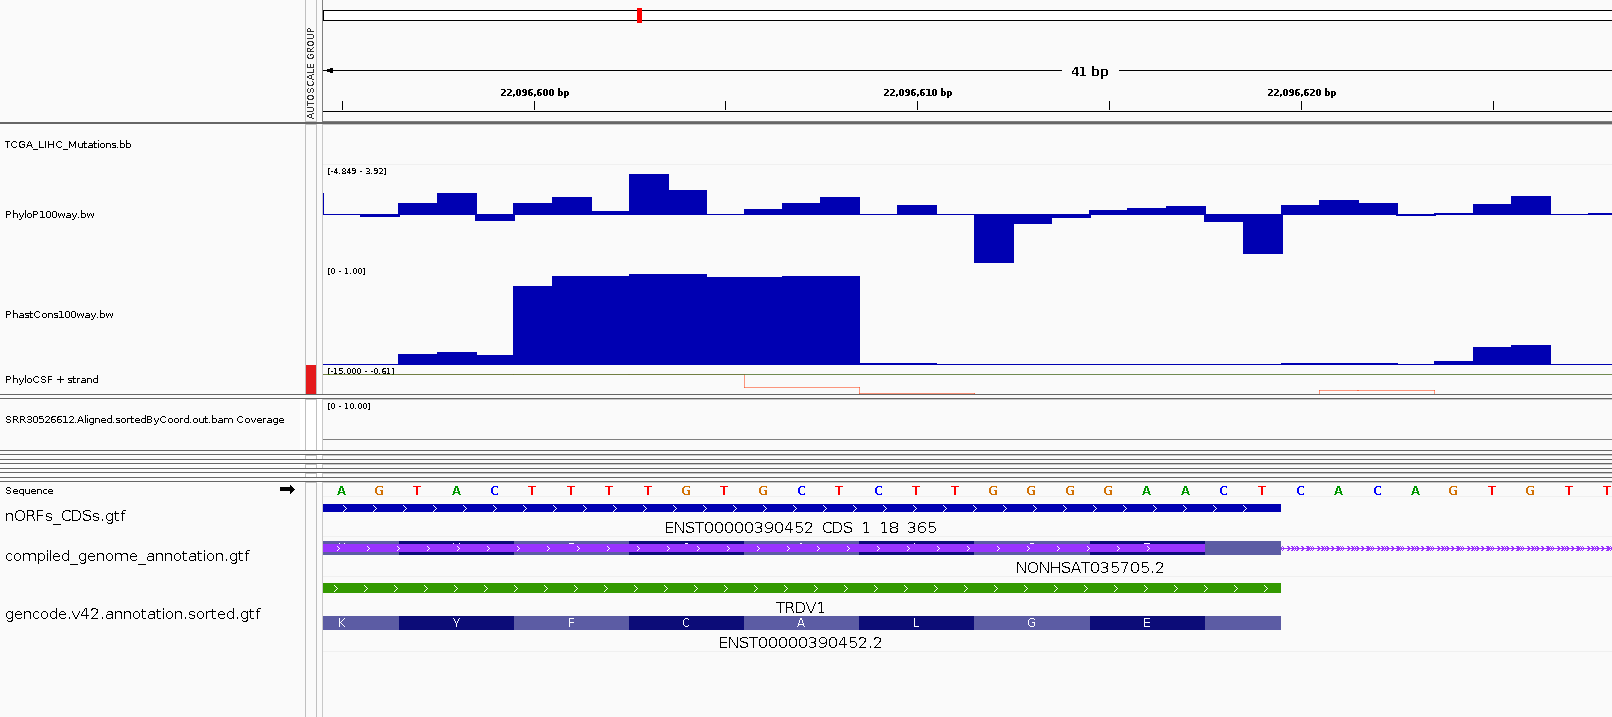

## Download public evolutationary conservation and mutation tracks from UCSC

In [ ]:
# 1. Prepare directories and define tracks
track_dir = subdirs["ext_data_dir"] + "conservation_and_mutations/"
os.makedirs(track_dir, exist_ok=True)

ucsc_base = "http://hgdownload.cse.ucsc.edu/goldenpath/hg38"
broad_base = "https://data.broadinstitute.org/compbio1/PhyloCSFtracks/hg38/latest"
ucsc_gbdb = "http://hgdownload.soe.ucsc.edu/gbdb/hg38"

# Dictionary format: { "TrackName": ("url", "extension") }
tracks_to_download = {
    "PhyloP100way": (f"{ucsc_base}/phyloP100way/hg38.phyloP100way.bw", "bw"),
    "PhastCons100way": (f"{ucsc_base}/phastCons100way/hg38.phastCons100way.bw", "bw"),
    "PhyloP30way": (f"{ucsc_base}/phyloP30way/hg38.phyloP30way.bw", "bw"),
    "PhastCons30way": (f"{ucsc_base}/phastCons30way/hg38.phastCons30way.bw", "bw"),
    
    # Population and Cancer Mutation Tracks (BigBed format)
    "gnomAD_Variants": (f"{ucsc_gbdb}/gnomAD/v3.1.1/genomes.bb", "bb"),
    "TCGA_LIHC_Mutations": (f"{ucsc_gbdb}/gdcCancer/LIHC.bb", "bb"),
    
    # PhyloCSF Power Track
    "PhyloCSF_Power": (f"{broad_base}/PhyloCSFpower.bw", "bw")
}

# Add PhyloCSF frame-specific tracks 
for strand, char in [('plus', '+'), ('minus', '-')]:
    for frame in [1, 2, 3]:
        url_char = "%2B" if char == "+" else "-"
        track_name = f"PhyloCSF{char}{frame}"
        tracks_to_download[track_name] = (f"{broad_base}/PhyloCSF{url_char}{frame}.bw", "bw")

# Generate and print download commands
command = f"mkdir -p {track_dir} && cd {track_dir}\n"
for track_name, (url, ext) in tracks_to_download.items():
    command += f"wget -c -O {track_name}.{ext} {url} \n"

print(command)
# Execute this in bash

## Specify association jobs accounting for track specifics

In [ ]:
organism = "human"

chrom_sizes = pd.read_csv(file_paths[organism + "_chrom_sizes_file"], sep='\t', header=None, names=['chrom', 'size'])
chrom_sizes_dict = dict(zip(chrom_sizes['chrom'], chrom_sizes['size']))

cds_df = exons_df.copy() # the exons in our case represent coding sequences, CDSs
cds_df['chrom'] = cds_df[0]
cds_df['start_0'] = cds_df[3].astype(int) - 1 # adhere to bed format
cds_df['end_1'] = cds_df[4].astype(int)
cds_df['strand'] = cds_df[6]

# --- Calculate accurate frames accounting for previous exon lengths ---
cds_df['length'] = cds_df['end_1'] - cds_df['start_0']
cds_df['sort_key'] = np.where(cds_df['strand'] == '+', cds_df['start_0'], -cds_df['start_0'])
cds_df = cds_df.sort_values(by=['gene_id', 'sort_key'])
cds_df['cum_len'] = cds_df.groupby('gene_id')['length'].cumsum() - cds_df['length']

def get_corrected_phylocsf_track(row):
    chrom = row['chrom']
    strand = row['strand']
    start_0 = row['start_0']
    end_1 = row['end_1']
    cum_len = int(row['cum_len'])
    offset = (3 - (cum_len % 3)) % 3
    
    if strand == '+':
        codon_start_0 = start_0 + offset
        frame = (codon_start_0 % 3) + 1
        return f"PhyloCSF+{frame}"
    elif strand == '-':
        if chrom in chrom_sizes_dict:
            codon_start_1 = end_1 - offset
            frame = ((chrom_sizes_dict[chrom] - codon_start_1) % 3) + 1
            return f"PhyloCSF-{frame}"
    return None

cds_df['phylocsf_track'] = cds_df.apply(get_corrected_phylocsf_track, axis=1)
cds_df.drop(columns=['length', 'sort_key', 'cum_len'], inplace=True)

bed_jobs_dir = subdirs["temp_dir"] + "conservation_bed_jobs/"
os.makedirs(bed_jobs_dir, exist_ok=True)

# 1. Genome-wide standard tracks
standard_tracks = [
    "PhyloP100way", "PhastCons100way", "PhyloP30way", "PhastCons30way", 
    "PhyloCSF_Power", "TCGA_LIHC_Mutations"
]

for track in standard_tracks:
    tmp_df = cds_df[['chrom', 'start_0', 'end_1', 'gene_id']].copy()
    tmp_df['track_name'] = track
    tmp_df.to_csv(f"{bed_jobs_dir}/{track}.bed", sep='\t', header=False, index=False)

# 2. Unified PhyloCSF BED (1 file, column 5 specifies exact track per exon)
tmp_csf = cds_df.dropna(subset=['phylocsf_track']).copy()
tmp_csf[['chrom', 'start_0', 'end_1', 'gene_id', 'phylocsf_track']].to_csv(
    f"{bed_jobs_dir}/PhyloCSF_Combined.bed", sep='\t', header=False, index=False
)
    
print(f"Generated BED files for SLURM jobs in {bed_jobs_dir}")

## Prepare .sbatch scripts to calculate various metrics for ORFs

In [ ]:
score_script = os.path.join(os.getcwd(),"analysis_scripts","compute_track_metrics.py")

sbatch_scripts = []
out_tables_dir = os.path.join(subdirs["tables_dir"],"HCC_ORFs","evol_and_genetics_track_scores")
os.makedirs(out_tables_dir, exist_ok=True)

# Add the Unified PhyloCSF track
all_tracks = standard_tracks + ["PhyloCSF_Combined"]

for track in all_tracks:
    sbatch_file_path = subdirs["slurm_scripts_dir"] + f"score_{track}.sbatch"
    
    with open(sbatch_file_path, "w") as f:
        command = f"""#!/bin/bash
#SBATCH --job-name=score_{track}
#SBATCH --time=05:59:00
#SBATCH --qos=6hours
#SBATCH --mem=8G
#SBATCH --cpus-per-task=1
#SBATCH --output={subdirs["slurm_dir"]}/score_{track}.%j.out
#SBATCH --error={subdirs["slurm_dir"]}/score_{track}.%j.err

source activate zavolab_pyutils

python {score_script} \\
    {bed_jobs_dir}/{track}.bed \\
    {track_dir} \\
    {out_tables_dir}/{track}_scores.tsv \\
    {track}
"""
        f.write(command)
    sbatch_scripts.append(sbatch_file_path)

print(";\n".join(["sbatch " + elem for elem in sbatch_scripts]))

In [ ]:
print(out_tables_dir) # here will be the outputs

## Import and parse the quantifications

In [ ]:
# Aggregate the SLURM output TSVs
all_scores_dfs = []
for track in all_tracks:
    res_path = f"{out_tables_dir}/{track}_scores.tsv"
    if os.path.exists(res_path):
        df = pd.read_csv(res_path, sep='\t')
        all_scores_dfs.append(df)

if all_scores_dfs:
    integration_df = all_scores_dfs[0]
    for df in all_scores_dfs[1:]:
        integration_df = pd.merge(integration_df, df, on="Geneid", how="outer")

    # Rename 'Geneid' to match the column name in genes_df 
    integration_df = integration_df.rename(columns={'Geneid': 'gene_id'})

    # Final Merge into the genes_df parsed from your basic annotation GTF
    final_genes_df = pd.merge(genes_df, integration_df, on="gene_id", how="left")
    
    print("Integration of Conservation & Mutation metrics successful!")
    display(final_genes_df.head(3))
else:
    print("No score tables found. Ensure SLURM jobs have completed successfully.")

In [ ]:
print(f'we assigned PhyloP for {len(final_genes_df.loc[~final_genes_df['PhyloP100way_Median'].isna()])}, and PhyloCSF for {len(final_genes_df.loc[~final_genes_df['PhyloCSF_Median'].isna()])} elements')
print(f'we have started with {len(transcript_coords_df)} ORFs and CDSs')

In [ ]:
final_genes_df['ORF_type'] = final_genes_df.apply(lambda x:x['gene_id'].split('_')[1],1)
subset_extract_dict = {1:'with_evidence',0:'no_evidence'}
final_genes_df['subset'] = final_genes_df.apply(lambda x:subset_extract_dict[int(x['gene_id'].split('_')[2])],1)
final_genes_df['ORF_category'] = final_genes_df['ORF_type']+';'+final_genes_df['subset']

## Make plots displaying evolutionary conservation patterns of ORFs

### Overall patterns

In [ ]:
final_genes_df['t']=1
final_genes_df.groupby(['ORF_category']).agg({'t':sum}).reset_index()

In [ ]:
from scipy.stats import ks_2samp

hue = 'ORF_category'

fig_file_name = 'evol_scores.nORFs_and_CDSs.eCDF.pdf'
hue_order = ['CDS;with_evidence','uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence','lincRNA;with_evidence','lincRNA;no_evidence']
palette = ['green','orangered','orange','royalblue','lightblue','darkviolet','mediumpurple','deeppink','pink']

# uncomment the following code to visualize ONLY nORFs
# fig_file_name = 'evol_scores.nORFs_only.pdf'
# hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence','lincRNA;with_evidence','lincRNA;no_evidence']
# palette = ['orangered','orange','royalblue','lightblue','darkviolet','mediumpurple','deeppink','pink']

# KS-test target pairs and their reporting color
ks_pairs = [
    ('uORF;with_evidence', 'uORF;no_evidence', 'orangered'),
    ('dORF;with_evidence', 'dORF;no_evidence', 'royalblue'),
    ('lincRNA;with_evidence', 'lincRNA;no_evidence', 'deeppink'),
    ('RT;with_evidence', 'RT;no_evidence', 'darkviolet')
]

# --- Text Layout Configuration per Feature ---
# Adjust x, start_y, alignments, and step direction (+ for upward, - for downward)
text_layout_config = {
    'PhyloP100way_Median':      {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhastCons100way_Median':   {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06},  # Bottom-right
    'PhyloP30way_Median':       {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhastCons30way_Median':    {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06},  # Bottom-right
    'PhyloCSF_Median': {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhyloCSF_Power_Median': {'x': 0.05, 'start_y': 0.95, 'ha': 'left',  'va': 'top', 'step': -0.06}, # Top-left
}

features = ['PhyloP100way_Median','PhastCons100way_Median','PhyloP30way_Median','PhastCons30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median']
feature_labels = ['PhyloP Median\n100 vertebrates','PhastCons Median\n100 vertebrates','PhyloP Median\n30 primates','PhastCons Median\n30 primates','PhyloCSF Median\n58-mammals','PhyloCSF POWER Median\n58-mammals']
xlims = [(-1,5),None,(-0.5,1.5),None,None,None]

sns.set(font_scale=1, style="white")
fig, axes = plt.subplots(1, len(features), sharey=True, sharex=False, figsize=(2.8*len(features),3.2))

for k, feature in enumerate(features):
    data = final_genes_df.loc[(~final_genes_df[feature].isna())].copy()
    print(f'{len(data)} ORFs for '+feature)
    
    ax = sns.ecdfplot(ax = axes[k],
                      data = data, x = feature, 
                      hue = hue, hue_order = hue_order, palette = palette,
                      alpha=1,
                     )
    
    ax.set(title = '', xlabel = feature_labels[k], ylabel = ('eCDF' if k==0 else ''))
    if xlims[k] is not None:
        ax.set(xlim = xlims[k])
    ax.tick_params(bottom=True, left=(True if k==0 else False))
    
    # --- Dynamic KS-test Annotation ---
    cfg = text_layout_config.get(feature, {'x': 0.95, 'start_y': 0.05, 'ha': 'right', 'va': 'bottom', 'step': 0.06})
    y_pos = cfg['start_y']
    
    for cat_with, cat_no, color in ks_pairs:
        dist_with = data.loc[data[hue] == cat_with, feature]
        dist_no = data.loc[data[hue] == cat_no, feature]
        
        if len(dist_with) > 0 and len(dist_no) > 0:
            stat, p_val = ks_2samp(dist_with, dist_no)
            
            if p_val < 0.001:
                p_text = f"p = {p_val:.2e}"
            else:
                p_text = f"p = {p_val:.3f}"
                
            label = cat_with.split(';')[0]
            text_str = f"{label}: {p_text}"
            
            ax.text(
                cfg['x'], y_pos, text_str, 
                color=color, 
                transform=ax.transAxes, 
                ha=cfg['ha'], 
                va=cfg['va'], 
                fontsize=8,
                weight='semibold'
            )
            # Adjust the vertical position for the next category line
            y_pos += cfg['step']
    # ----------------------------------

    if k < len(features)-1:
        ax.legend_.remove()
    else:
        sns.move_legend(
                    ax, 
                    loc="upper left", 
                    bbox_to_anchor=(1.05, 1), 
                    borderaxespad=0.0, 
                    title='ORF category'
                )

savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.tight_layout(pad=0.5)
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
from scipy.stats import ks_2samp

hue = 'ORF_category'

fig_file_name = 'evol_scores.nORFs_and_CDSs.histogram.pdf'
hue_order = ['CDS;with_evidence','uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence','lincRNA;with_evidence','lincRNA;no_evidence']
palette = ['green','orangered','orange','royalblue','lightblue','darkviolet','mediumpurple','deeppink','pink']

# uncomment the following code to visualize ONLY nORFs
# fig_file_name = 'evol_scores.nORFs_only.pdf'
# hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence','lincRNA;with_evidence','lincRNA;no_evidence']
# palette = ['orangered','orange','royalblue','lightblue','darkviolet','mediumpurple','deeppink','pink']

# KS-test target pairs and their reporting color
ks_pairs = [
    ('uORF;with_evidence', 'uORF;no_evidence', 'orangered'),
    ('dORF;with_evidence', 'dORF;no_evidence', 'royalblue'),
    ('lincRNA;with_evidence', 'lincRNA;no_evidence', 'deeppink'),
    ('RT;with_evidence', 'RT;no_evidence', 'darkviolet')
]

# --- Text Layout Configuration per Feature ---
# Adjust x, start_y, alignments, and step direction (+ for upward, - for downward)
text_layout_config = {
    'PhyloP100way_Median':      {'x': 0.95, 'start_y': 0.95, 'ha': 'right',  'va': 'top', 'step': -0.06}, 
    'PhastCons100way_Median':   {'x': 0.5, 'start_y': 0.95, 'ha': 'center',  'va': 'top', 'step': -0.06},
    'PhyloP30way_Median':       {'x': 0.5, 'start_y': 0.95, 'ha': 'center',  'va': 'top', 'step': -0.06},
    'PhastCons30way_Median':    {'x': 0.5, 'start_y': 0.95, 'ha': 'center',  'va': 'top', 'step': -0.06},
    'PhyloCSF_Median': {'x': 0.5, 'start_y': 0.95, 'ha': 'center',  'va': 'top', 'step': -0.06}, 
    'PhyloCSF_Power_Median': {'x': 0.05, 'start_y': 0.95, 'ha': 'left',  'va': 'top', 'step': -0.06}, # Top-left
}

features = ['PhyloP100way_Median','PhastCons100way_Median','PhyloP30way_Median','PhastCons30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median']
feature_labels = ['PhyloP Median\n100 vertebrates','PhastCons Median\n100 vertebrates','PhyloP Median\n30 primates','PhastCons Median\n30 primates','PhyloCSF Median\n58-mammals','PhyloCSF POWER Median\n58-mammals']
xlims = [(-1,8),None,(-0.5,1.5),None,None,None]

sns.set(font_scale=1, style="white")
fig, axes = plt.subplots(1, len(features), sharey=False, sharex=False, figsize=(2.8*len(features),3.2))

for k, feature in enumerate(features):
    data = final_genes_df.loc[(~final_genes_df[feature].isna())].copy()
    print(f'{len(data)} ORFs for '+feature)

    min_val,max_val = data[feature].min(),data[feature].max()
    bin_step = (max_val-min_val)/30
    ax = sns.histplot(ax = axes[k],
                      data = data, x = feature, 
                      hue = hue, hue_order = hue_order, palette = palette,
                      common_norm = False,common_bins=True,element="step",stat="density",
                      bins = np.arange(min_val,max_val+0.01,bin_step),fill=True,
                      alpha=0.05,
                     )
    
    ax.set(title = '', xlabel = feature_labels[k], ylabel = ('density' if k==0 else ''))
    if xlims[k] is not None:
        ax.set(xlim = xlims[k])
    ax.tick_params(bottom=True, left=True)
    
    # --- Dynamic KS-test Annotation ---
    cfg = text_layout_config.get(feature, {'x': 0.95, 'start_y': 0.05, 'ha': 'right', 'va': 'bottom', 'step': 0.06})
    y_pos = cfg['start_y']
    
    for cat_with, cat_no, color in ks_pairs:
        dist_with = data.loc[data[hue] == cat_with, feature]
        dist_no = data.loc[data[hue] == cat_no, feature]
        
        if len(dist_with) > 0 and len(dist_no) > 0:
            stat, p_val = ks_2samp(dist_with, dist_no)
            
            if p_val < 0.001:
                p_text = f"p = {p_val:.2e}"
            else:
                p_text = f"p = {p_val:.3f}"
                
            label = cat_with.split(';')[0]
            text_str = f"{label}: {p_text}"
            
            ax.text(
                cfg['x'], y_pos, text_str, 
                color=color, 
                transform=ax.transAxes, 
                ha=cfg['ha'], 
                va=cfg['va'], 
                fontsize=8,
                weight='semibold'
            )
            # Adjust the vertical position for the next category line
            y_pos += cfg['step']
    # ----------------------------------

    if k < len(features)-1:
        ax.legend_.remove()
    else:
        sns.move_legend(
                    ax, 
                    loc="upper left", 
                    bbox_to_anchor=(1.05, 1), 
                    borderaxespad=0.0, 
                    title='ORF category'
                )

savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.tight_layout(pad=0.5)
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
final_genes_df.loc[(final_genes_df['ORF_category']=='CDS;with_evidence')&(final_genes_df['PhyloCSF_Median']< -8)].head()['gene_name']

In [ ]:
cds_df.loc[cds_df['gene_name'] == 'ENSG00000270099']

some CDSs have wrongly-annotated start codons, which results in low PhyloCSF scores, e.g. here:

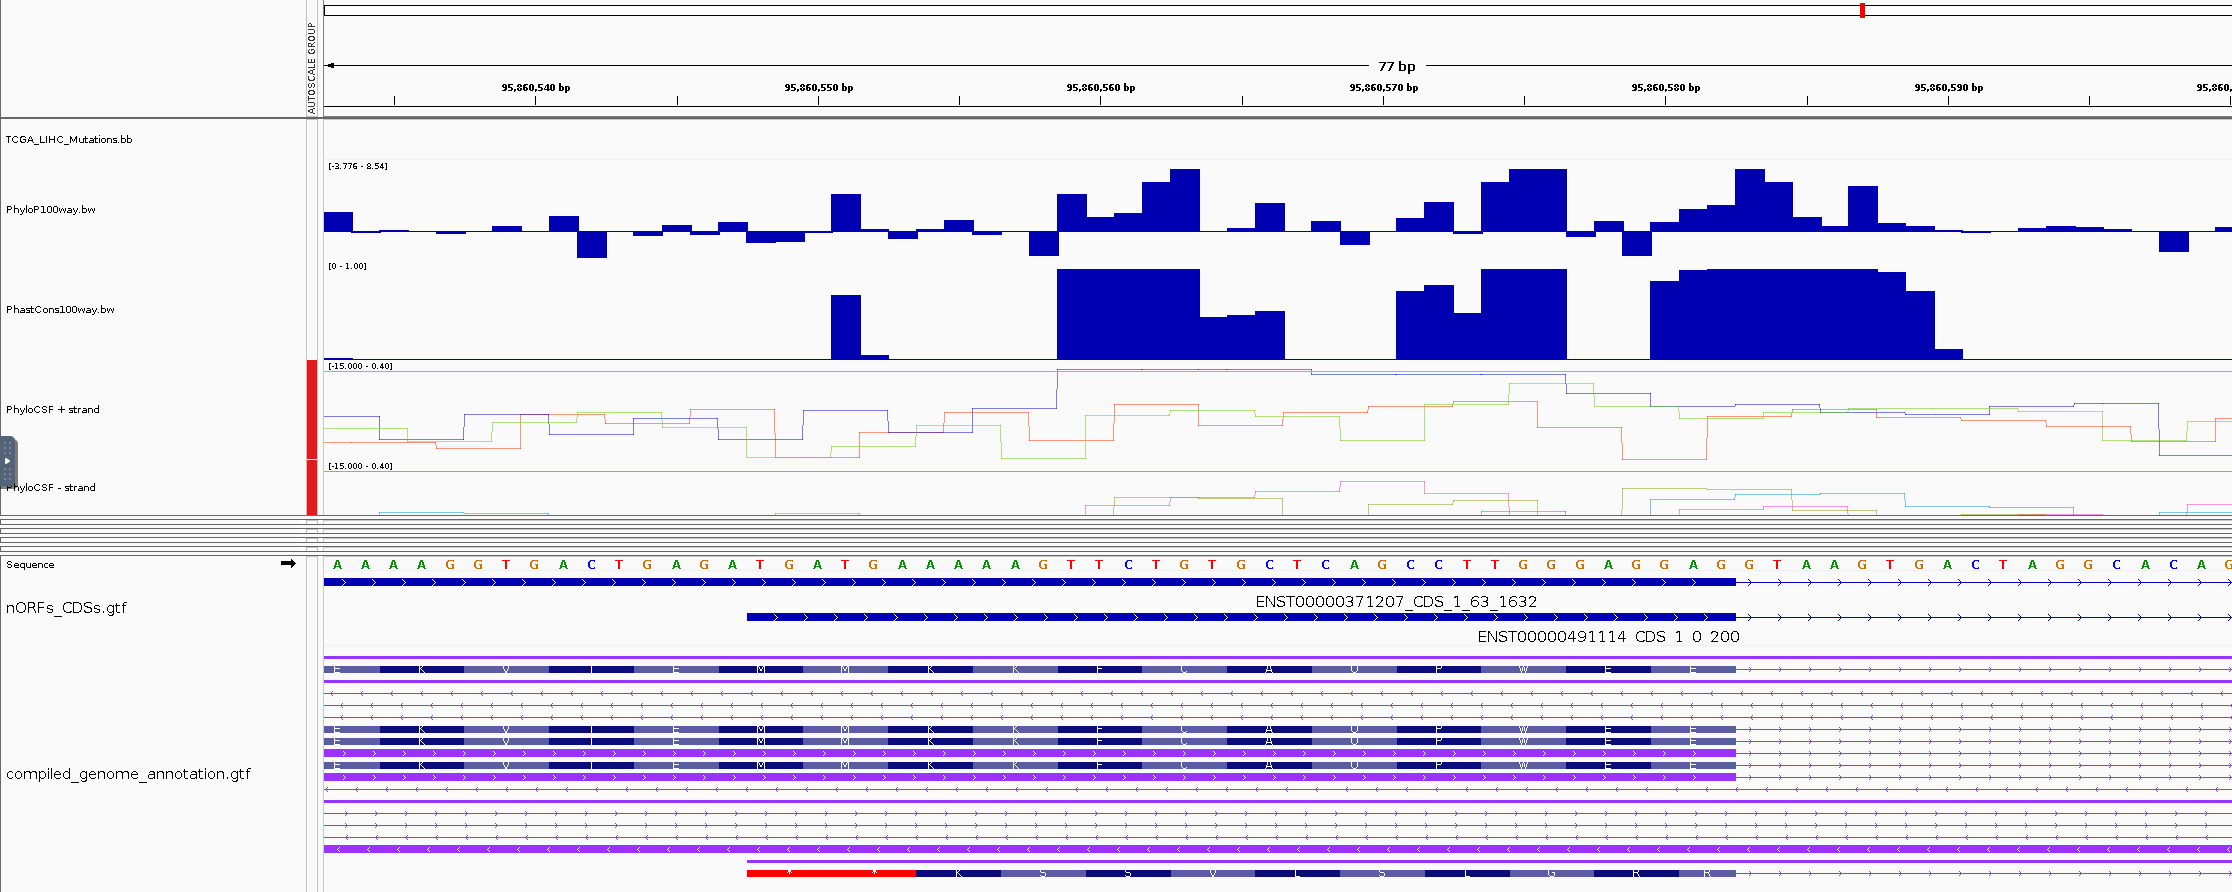

now bin all ORFs into groups by their exonic lengths

### Check most conserved targets 

In [ ]:
sel_targets_df = final_genes_df.loc[(final_genes_df['PhyloCSF_Median']>2)&(final_genes_df['ORF_type']!='CDS')].copy()
sel_targets_df['t'] = 1
display(sel_targets_df.groupby(['ORF_category']).agg({'t':sum}).reset_index())

In [ ]:
# define feature_id to allow for joining from the TPM data frames or Deseq outputs
sel_targets_df['Feature_ID'] = sel_targets_df.apply(lambda x:'_'.join(list(pd.Series(x['gene_id'].split('_'))[[0,3,4]])),1)

#### uORFs

In [ ]:
# append results of log2FC of uORF/CDS ratio

tmp1_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_uorf_NonViral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)
tmp2_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_uorf_Viral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)

uORF_targets_df = sel_targets_df.loc[sel_targets_df['ORF_category']=='uORF;with_evidence'][
        [0,3,4,6,8,'Feature_ID','gene_name','PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median','TCGA_LIHC_Mutations_Count']].sort_values('PhyloCSF_Median',ascending=False)

rename_dict = {'log2FoldChange':'log2FoldChange_NONviral','pvalue':'pvalue_NONviral','padj':'padj_NONviral'}
uORF_targets_df = pd.merge(uORF_targets_df,
                           tmp1_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')
rename_dict = {'log2FoldChange':'log2FoldChange_viral','pvalue':'pvalue_viral','padj':'padj_viral'}
uORF_targets_df = pd.merge(uORF_targets_df,
                           tmp2_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')

In [ ]:
uORF_targets_df

#### dORFs

In [ ]:
tmp1_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_dorf_NonViral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)
tmp2_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_dorf_Viral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)

dORF_targets_df = sel_targets_df.loc[sel_targets_df['ORF_category']=='dORF;with_evidence'][
        [0,3,4,6,8,'Feature_ID','gene_name','PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median','TCGA_LIHC_Mutations_Count']].sort_values('PhyloCSF_Median',ascending=False)

rename_dict = {'log2FoldChange':'log2FoldChange_NONviral','pvalue':'pvalue_NONviral','padj':'padj_NONviral'}
dORF_targets_df = pd.merge(dORF_targets_df,
                           tmp1_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')
rename_dict = {'log2FoldChange':'log2FoldChange_viral','pvalue':'pvalue_viral','padj':'padj_viral'}
dORF_targets_df = pd.merge(dORF_targets_df,
                           tmp2_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')

In [ ]:
', '.join(list(dORF_targets_df['gene_name'].unique()))

In [ ]:
dORF_targets_df

In [ ]:
sel_targets_df.loc[sel_targets_df['ORF_category']=='RT;with_evidence'][
        [0,3,4,6,8,'gene_name','PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median','TCGA_LIHC_Mutations_Count']].sort_values('PhyloCSF_Median',ascending=False)

In [ ]:
sel_targets_df.loc[sel_targets_df['ORF_category']=='lincRNA;with_evidence'][
        [0,3,4,6,8,'gene_name','PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median','TCGA_LIHC_Mutations_Count']].sort_values('PhyloCSF_Median',ascending=False)

### Dependency on ORF length

In [ ]:
# also need to calculate the total exonic length for gene id to normalize
exons_df['len'] = exons_df[4]-exons_df[3]+1
if 'len' in final_genes_df.columns:
    final_genes_df = final_genes_df.drop(['len'],axis = 1)
final_genes_df = pd.merge(final_genes_df,
         exons_df.groupby('gene_id').agg({'len':sum}).reset_index(),
         how='left',on='gene_id')

In [ ]:
# --- Stratifying Length Confounder (Value-based Binning) ---
bin_edges = [0, 50, 100, 300, np.inf]
final_genes_df['len_bin'] = pd.cut(final_genes_df['len'], bins=bin_edges)

unique_bins = sorted(final_genes_df['len_bin'].dropna().unique())
bin_labels = {
    b: f"{max(0, int(b.left))}-{int(b.right) if b.right != np.inf else 'max'}" 
    for b in unique_bins
}

# --- Core Setup Configuration ---
fig_file_name = 'evol_scores.nORFs_only.stratified_by_ORF_length.uORFs_dORFs.pdf'

hue = 'ORF_category'
# hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence','lincRNA;with_evidence','lincRNA;no_evidence']
# palette = ['orangered','orange','royalblue','lightblue','darkviolet','mediumpurple','deeppink','pink']
hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence']
palette = ['orangered','orange','royalblue','lightblue']



ks_pairs = [
    ('uORF;with_evidence', 'uORF;no_evidence', 'orangered'),
    ('dORF;with_evidence', 'dORF;no_evidence', 'royalblue'),
    ('lincRNA;with_evidence', 'lincRNA;no_evidence', 'deeppink'),
    ('RT;with_evidence', 'RT;no_evidence', 'darkviolet')
]

text_layout_config = {
    'PhyloP100way_Median':      {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhastCons100way_Median':   {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06},  # Bottom-right
    'PhyloP30way_Median':       {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhastCons30way_Median':    {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06},  # Bottom-right
    'PhyloCSF_Median': {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhyloCSF_Power_Median': {'x': 0.05, 'start_y': 0.95, 'ha': 'left',  'va': 'top', 'step': -0.06}, # Top-left
}

features = ['PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median']
feature_labels = ['PhyloP Median\n100 vertebrates','PhyloP Median\n30 primates','PhyloCSF Median\n58-mammals','PhyloCSF POWER Median\n58-mammals']
xlims = [(-0.2,2), (-0.2,1.2), (-8,-5), None]

# =========================================================================
# NEW: Global Proportions Normalization (Across Bins per Category)
# =========================================================================
# 1. Get raw counts grid (Rows: Category, Columns: Length Bins)
counts_matrix = final_genes_df.groupby([hue, 'len_bin'], observed=False).size().unstack(fill_value=0)

# 2. Divide each row by its total sum (Normalizes across length bins for every category)
normalized_matrix = counts_matrix.div(counts_matrix.sum(axis=1), axis=0)

# 3. Flatten back into a long-form DataFrame for Seaborn mapping
global_prop_df = normalized_matrix.stack().reset_index(name='proportion')


# --- Initialize 2D Subplot Grid ---
num_rows = len(unique_bins)
num_cols = len(features) + 1  
sns.set(font_scale=1, style="white")

fig, axes = plt.subplots(
    nrows=num_rows, 
    ncols=num_cols, 
    sharey=False,       
    sharex=False,       
    figsize=(3.2 * num_cols, 2.2 * num_rows)
)

# --- Grid Traversal Loop ---
for r, bin_val in enumerate(unique_bins):
    row_data = final_genes_df.loc[final_genes_df['len_bin'] == bin_val]
    row_range_str = bin_labels[bin_val]
    
    # =========================================================================
    # COLUMN 0: Relative Proportion Barplots (Corrected Normalization)
    # =========================================================================
    ax_count = axes[r, 0]
    
    # Filter precalculated global proportions for just this length tier row
    prop_df = global_prop_df[global_prop_df['len_bin'] == bin_val]
    
    sns.barplot(
        ax=ax_count, data=prop_df, x=hue, y='proportion', order=hue_order, palette=palette
    )
    
    ax_count.set_ylim(0, 1.0)
    ax_count.set_ylabel(f"Proportion\n(Len: {row_range_str} bp)", fontsize=9)
    ax_count.set_xlabel("" if r == num_rows - 1 else "")
    ax_count.set_xticklabels([]) 
    ax_count.tick_params(bottom=False, left=True)
    
    # =========================================================================
    # COLUMNS 1 to N: Evolutionary Metric eCDF Subplots
    # =========================================================================
    for c_feat, feature in enumerate(features):
        c = c_feat + 1  
        ax = axes[r, c]
        data = row_data.loc[~row_data[feature].isna()].copy()
        
        sns.ecdfplot(
            ax=ax, data=data, x=feature, 
            hue=hue, hue_order=hue_order, palette=palette, alpha=1
        )
        
        ax.set_ylim(-0.02, 1.02)

        ax.set_ylabel("eCDF" if c == 1 else "")
        ax.set_xlabel(feature_labels[c_feat] if r == num_rows - 1 else "")
        
        if xlims[c_feat] is not None:
            ax.set(xlim=xlims[c_feat])
            
        ax.tick_params(bottom=True, left=True)
        
        # --- Context-Specific KS-test Calculations ---
        cfg = text_layout_config.get(feature, {'x': 0.95, 'start_y': 0.05, 'ha': 'right', 'va': 'bottom', 'step': 0.06})
        y_pos = cfg['start_y']
        
        for cat_with, cat_no, color in ks_pairs:
            dist_with = data.loc[data[hue] == cat_with, feature]
            dist_no = data.loc[data[hue] == cat_no, feature]
            
            if len(dist_with) > 5 and len(dist_no) > 5:
                stat, p_val = ks_2samp(dist_with, dist_no)
                p_text = f"p = {p_val:.2e}" if p_val < 0.001 else f"p = {p_val:.3f}"
                label = cat_with.split(';')[0]
                
                ax.text(
                    cfg['x'], y_pos, f"{label}: {p_text}", 
                    color=color, transform=ax.transAxes, 
                    ha=cfg['ha'], va=cfg['va'], 
                    fontsize=7.5, weight='semibold'
                )
                y_pos += cfg['step']
                
        # --- Legend Sanitization ---
        if r == 0 and c == num_cols - 1:
            sns.move_legend(
                ax, loc="upper left", bbox_to_anchor=(1.05, 1), 
                borderaxespad=0.0, title='ORF category'
            )
        else:
            if ax.legend_ is not None:
                ax.legend_.remove()

# --- File Serialization ---
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
Path(savefig_path).parent.mkdir(parents=True, exist_ok=True)

fig.tight_layout(pad=0.6)
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

### Juxtaposing conservation of nORF and main CDS

In [ ]:
final_genes_df.head()

In [ ]:
final_genes_df['host_transcript_id'] = final_genes_df.apply(lambda x:x['gene_id'].split('_')[0],1)

features = ['PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median']
feature_labels = ['PhyloP Median\n100 vertebrates','PhyloP Median\n30 primates','PhyloCSF Median\n58-mammals','PhyloCSF POWER Median\n58-mammals']

tmp1_df = final_genes_df.loc[final_genes_df['ORF_type'].isin(['uORF', 'dORF'])][['host_transcript_id','gene_id','ORF_type','ORF_category','gene_name']+features]
rename_dict = {}
for elem in features:
    rename_dict[elem] = elem+';nORF'
tmp1_df = tmp1_df.rename(columns=rename_dict)

tmp2_df = final_genes_df.loc[final_genes_df['ORF_type'].isin(['CDS'])][['host_transcript_id']+features]
rename_dict = {}
for elem in features:
    rename_dict[elem] = elem+';CDS'
tmp2_df = tmp2_df.rename(columns=rename_dict)
juxtaposed_df = pd.merge(tmp1_df,tmp2_df,how='left',on='host_transcript_id')

# add transciptomic coordinates to see the dependency on the distance and other factors
nORFs_df['nORF_len'] = nORFs_df['end']-nORFs_df['start']
CDSs_df['CDS_len'] = CDSs_df['end']-CDSs_df['start']

rename_coords_dict = {'start':'start_tx_nORF','end':'end_tx_nORF','custom_transcript_id':'gene_id'}
juxtaposed_df = pd.merge(juxtaposed_df,nORFs_df[['custom_transcript_id','start','end','nORF_len']].rename(columns=rename_coords_dict),how='left',on='gene_id')
rename_coords_dict = {'start':'start_tx_CDS','end':'end_tx_CDS','transcript_id':'host_transcript_id'}
juxtaposed_df = pd.merge(juxtaposed_df,CDSs_df[['transcript_id','start','end','CDS_len']].rename(columns=rename_coords_dict),how='left',on='host_transcript_id')

print(f'check that no artefact is introduced during joining: after: {len(juxtaposed_df)} , before: {len(final_genes_df.loc[final_genes_df['ORF_type'].isin(['uORF', 'dORF','RT'])])}')

juxtaposed_df['distance_to_main_CDS'] = np.nan
orf_base_type = juxtaposed_df['ORF_type']

# Mask 1: Assign uORFs
uorf_mask = (orf_base_type == 'uORF')
juxtaposed_df.loc[uorf_mask, 'distance_to_main_CDS'] = (
    juxtaposed_df.loc[uorf_mask, 'end_tx_nORF'] - juxtaposed_df.loc[uorf_mask, 'start_tx_CDS']
)

# Mask 2: Assign dORFs and RTs
dorf_rt_mask = orf_base_type.isin(['dORF', 'RT'])
juxtaposed_df.loc[dorf_rt_mask, 'distance_to_main_CDS'] = (
    juxtaposed_df.loc[dorf_rt_mask, 'start_tx_nORF'] - juxtaposed_df.loc[dorf_rt_mask, 'end_tx_CDS']
)

display(juxtaposed_df.head())

In [ ]:
hue = 'ORF_category'
hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence']
palette = ['orangered','orange','royalblue','lightblue']
xlims = [(-1000,200),(-1000,200),(-10,2500),(-10,2500)]
ylims = [(0,800),(0,800),(0,800),(0,800)]

x_feature,y_feature = 'distance_to_main_CDS','nORF_len'

sns.set(font_scale=1)
sns.set_style("white")
bw_adjust = 1.75

for k,hue_val in enumerate(hue_order):
    data = juxtaposed_df.loc[juxtaposed_df[hue]==hue_val].copy()
    g = sns.jointplot(data = data,
                      height = 3,
                              x=x_feature,y=y_feature,s=10,
                              color = palette[k],
                              alpha=0.3)
    ax = g.ax_joint
    ax = sns.kdeplot(
            data=data,
            x=x_feature,
            y=y_feature,
            fill=False,
        levels=[0.1, 0.25, 0.5],
        cut = 0,
        bw_adjust=bw_adjust,
        color='blue',label='50%, 75%, and 90% 2D contours')
    ax.tick_params(bottom=True,left=True)
    ax.set(xlabel = x_feature+'\n'+hue_val)
    if xlims[k] is not None:
        ax.set(xlim = xlims[k])
    if ylims[k] is not None:
        ax.set(ylim = ylims[k])
    savefig_path = savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs','nORF_rel_location', hue_val+'.png')
    # Create parent directories if they do not exist
    dir_path = Path(savefig_path).parent
    dir_path.mkdir(parents=True, exist_ok=True)
    
    g.savefig(savefig_path, bbox_inches='tight', dpi=600)

**append expression information**

In [ ]:
HCC_RiboSeq_samples_metadata_df = pd.read_csv(os.path.join(subdirs['ext_data_dir'],'HCC_paper_metadata','Suppl_Table_1_forResubmission.xlsx - Ribo-seq Samples.tsv'), index_col=None, header=0,delimiter="\t")

HCC_RiboSeq_samples_metadata_df['Liver disease background'].unique()
etiology_classification_dict = {
    'HCV':'viral',
    'HBV':'viral',
    'NASH':'non-viral',
    'ASH':'non-viral',
    'ASH/NASH':'non-viral'
}
HCC_RiboSeq_samples_metadata_df['etiology'] = HCC_RiboSeq_samples_metadata_df['Liver disease background'].map(etiology_classification_dict)
HCC_RiboSeq_samples_metadata_df['sample_id'] = HCC_RiboSeq_samples_metadata_df['Biobank ID'].str.replace('-','_')
HCC_RiboSeq_samples_metadata_df['sample_type'] = HCC_RiboSeq_samples_metadata_df.apply(lambda x:'NT' if '_NT' in x['sample_id'] else 'T',1)

In [ ]:
CDS_uORF_dORF_TPM_values_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'CDS_uORF_dORF_TPM_values.tsv'), index_col=None, header=0,delimiter="\t",)
NT_cols_viral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='NT')]['sample_id'])
NT_cols_NONviral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='non-viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='NT')]['sample_id'])

cols = list(CDS_uORF_dORF_TPM_values_df.columns)
NT_cols_viral = [elem for elem in NT_cols_viral if elem in cols]
NT_cols_NONviral = [elem for elem in NT_cols_NONviral if elem in cols]

print('the following non-viral samples were used: '+', '.join(NT_cols_NONviral))
print('the following viral samples were used: '+', '.join(NT_cols_viral))

In [ ]:
# compare TPM in NT samples for viral and non-viral

ORF_types = list(CDS_uORF_dORF_TPM_values_df['Element'].unique())
for ORF_type in ORF_types:
    is_cur_ORF_type = CDS_uORF_dORF_TPM_values_df['Element'] == ORF_type
    
    data = CDS_uORF_dORF_TPM_values_df.loc[is_cur_ORF_type].copy()
    print(f'looking at {len(data)} {ORF_type}s')
    # recalculate TPM to look only at CDSs
    data[NT_cols_viral+NT_cols_NONviral] = data[NT_cols_viral+NT_cols_NONviral].div(data[NT_cols_viral+NT_cols_NONviral].sum(),axis=1)*10**6
    
    expr_feature_viral, expr_feature_NONviral = 'NT_mean_viral_TPM','NT_mean_NONviral_TPM'
    data[expr_feature_viral] = data[NT_cols_viral].mean(axis=1) # at low sample size, mean is more stable than median
    data[expr_feature_NONviral] = data[NT_cols_NONviral].mean(axis=1)
    top_border = np.quantile(data[[expr_feature_viral,expr_feature_NONviral]].mean(axis=1),q=0.99)
    
    data = data.loc[(data[[expr_feature_viral,expr_feature_NONviral]].min(axis=1)>0)&(
        data[[expr_feature_viral,expr_feature_NONviral]].mean(axis=1)<=top_border
    )] # look at a quantifiable subset
    
    # additionally scale to maintain the property of summing up to the same value
    data[expr_feature_viral] = data[expr_feature_viral]/data[expr_feature_viral].sum()*10**6
    data[expr_feature_NONviral] = data[expr_feature_NONviral]/data[expr_feature_NONviral].sum()*10**6

    print(data[[expr_feature_viral,expr_feature_NONviral]].sum())
    print(data[[expr_feature_viral,expr_feature_NONviral]].mean())
    print(data[[expr_feature_viral,expr_feature_NONviral]].median())
    data[[expr_feature_viral,expr_feature_NONviral]] = np.log2(data[[expr_feature_viral,expr_feature_NONviral]])
    
    print(f'left with {len(data)} {ORF_type}s after requiring quantifiable expression')
    
    x_feature,y_feature = expr_feature_viral,expr_feature_NONviral
    x_label,y_label = 'viral'+'\nmean TO in NT samples,\n'+str(len(data))+' '+ORF_type+'s','non-viral'

    min_value,max_value = min(data[[x_feature,y_feature]].mean(axis=1)),max(data[[x_feature,y_feature]].mean(axis=1))
    g = sns.jointplot(data = data,
                      height = 5,
                              x=x_feature,y=y_feature,s=10,
                              color = 'grey',
                              alpha=0.3,
                     marginal_kws=dict(bins=np.arange(min_value,max_value,(max_value-min_value)/50)),
    )
    ax = g.ax_joint
    ### add diagonal
    R2 = sklearn.metrics.r2_score(y_true=data[y_feature],y_pred=data[x_feature])
    ax = sns.lineplot(data = pd.DataFrame([[ax.get_xlim()[0],ax.get_xlim()[0]],[ax.get_xlim()[1],ax.get_xlim()[1]]],columns=[x_feature,y_feature]),
                      x=x_feature,y=y_feature,color='orange',label='diag'+'\n$R^2='+str(np.round(R2,2))+'$')
    
    ### add contours
    ax = sns.kdeplot(
                    data=data,
                    x=x_feature,
                    y=y_feature,
                    fill=False,
                levels=[0.1, 0.25, 0.5],
                bw_adjust=bw_adjust,
                color='blue',label='50%, 75%, and 90% 2D contours',
                cut = 0,
    )
    top_border_lim = np.quantile(data[[x_feature,y_feature]].mean(axis=1),q=0.95)
    ax.set(xlabel = x_label, ylabel = y_label, 
           # xlim = (0,top_border_lim),ylim = (0,top_border_lim)
          )
    ax.tick_params(bottom=True,left=True)
    
    savefig_path = savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', ORF_type+'s_expression_in_NT.RiboSeq.NONviral_vs_viral.log2_scale.png')
    # Create parent directories if they do not exist
    dir_path = Path(savefig_path).parent
    dir_path.mkdir(parents=True, exist_ok=True)
    
    g.savefig(savefig_path, bbox_inches='tight', dpi=600)

In [ ]:
# now, append TPM values to conservation scores
data = CDS_uORF_dORF_TPM_values_df.copy()
print(f'looking at {len(data)} elements')
# recalculate TPM (to double-check)
data[NT_cols_viral+NT_cols_NONviral] = data[NT_cols_viral+NT_cols_NONviral].div(data[NT_cols_viral+NT_cols_NONviral].sum(),axis=1)*10**6

expr_feature_viral, expr_feature_NONviral = 'NT_mean_viral_TPM','NT_mean_NONviral_TPM'
data[expr_feature_viral] = data[NT_cols_viral].mean(axis=1) # at low sample size, mean is more stable than median
data[expr_feature_NONviral] = data[NT_cols_NONviral].mean(axis=1)
top_border = np.quantile(data[[expr_feature_viral,expr_feature_NONviral]].mean(axis=1),q=0.99)

data = data.loc[(data[[expr_feature_viral,expr_feature_NONviral]].min(axis=1)>0)&(
    data[[expr_feature_viral,expr_feature_NONviral]].mean(axis=1)<=top_border
)] # look at a quantifiable subset, exclude too highly expressed and too lowly expressed elements

# additionally re-scale to maintain the property of summing up to the same value
data[expr_feature_viral] = data[expr_feature_viral]/data[expr_feature_viral].sum()*10**6
data[expr_feature_NONviral] = data[expr_feature_NONviral]/data[expr_feature_NONviral].sum()*10**6

In [ ]:
rename_dict = {'feature_id':'host_transcript_id',expr_feature_viral:expr_feature_viral+';CDS',expr_feature_NONviral:expr_feature_NONviral+';CDS'}
juxtaposed_df = pd.merge(juxtaposed_df,
    data.loc[data['Element']=='CDS'][['feature_id',expr_feature_viral, expr_feature_NONviral]].rename(columns=rename_dict),
         how='left',on='host_transcript_id')

In [ ]:
# define feature_id to allow for joining from the TPM data frame
juxtaposed_df['feature_id'] = juxtaposed_df.apply(lambda x:'_'.join(list(pd.Series(x['gene_id'].split('_'))[[0,3,4]])),1)

In [ ]:
rename_dict = {expr_feature_viral:expr_feature_viral+';nORF',expr_feature_NONviral:expr_feature_NONviral+';nORF'}
juxtaposed_df = pd.merge(juxtaposed_df,
    data.loc[data['Element']!='CDS'][['feature_id',expr_feature_viral, expr_feature_NONviral]].rename(columns=rename_dict),
         how='left',on='feature_id')

**Note**: for "no_evidence" category, there are no entries for TPM values

In [ ]:
juxtaposed_df.loc[juxtaposed_df['NT_mean_viral_TPM;nORF'].isna()].head()

In [ ]:
len(juxtaposed_df.loc[~juxtaposed_df['NT_mean_viral_TPM;nORF'].isna()])

calculate TPM ratios - those should primarily reflect the intensity of nORF usage

In [ ]:
juxtaposed_df['viral;ratio_log2'] = np.log2(juxtaposed_df[expr_feature_viral+';nORF']/juxtaposed_df[expr_feature_viral+';CDS'])
juxtaposed_df['NONviral;ratio_log2'] = np.log2(juxtaposed_df[expr_feature_NONviral+';nORF']/juxtaposed_df[expr_feature_NONviral+';CDS'])

In [ ]:
juxtaposed_df.loc[~juxtaposed_df['NT_mean_viral_TPM;nORF'].isna()].head()

In [ ]:
features

In [ ]:
# Now see the dependencies of Evolutionary conservation metrics
juxtaposed_df_copy = juxtaposed_df.copy()

hue = 'ORF_category'
hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence']
palette = ['orangered','orange','royalblue','lightblue']

x_features = ['nORF_len','CDS_len','distance_to_main_CDS','NT_mean_NONviral_TPM;CDS','NT_mean_NONviral_TPM;nORF','NT_mean_viral_TPM;CDS','NT_mean_viral_TPM;nORF','viral;ratio_log2','NONviral;ratio_log2']
x_features = x_features+[elem+';CDS' for elem in features] # add conservation features at CDS for control

sns.set(font_scale=1)
sns.set_style("white")
bw_adjust = 1.75

results_list = []
for x_feature in x_features: # presumable explanatory variables or confounders
    for k1,y_feature in enumerate(features): # those are evolutionary metrics
        y_feature = y_feature+';nORF' # look at nORF
        for k,hue_val in enumerate(hue_order):
            hue_filter = juxtaposed_df_copy[hue] == hue_val
            y_feature_filter = (~juxtaposed_df_copy[y_feature].isna())
            x_feature_filter = (~juxtaposed_df_copy[x_feature].isna())
            
            data = juxtaposed_df_copy.loc[hue_filter & y_feature_filter & x_feature_filter].copy()
            if len(data)>0:
                g = sns.jointplot(data = data,
                                  height = 5,
                                          x=x_feature,y=y_feature,s=10,
                                          color = palette[k],
                                          alpha=0.3,
                                 marginal_kws=dict(bins=20),
                )            
                ax = g.ax_joint            
                ### add contours
                ax = sns.kdeplot(
                                data=data,
                                x=x_feature,
                                y=y_feature,
                                fill=False,
                            levels=[0.1, 0.25, 0.5],
                            bw_adjust=bw_adjust,
                            color='blue',label='50%, 75%, and 90% 2D contours',
                            cut = 0,
                )
                ax.set(xlabel = x_feature+'\n'+hue_val,ylabel = feature_labels[k1]+'\nat nORF', )
                ax.set(
                       xlim = (np.quantile(data[x_feature],q=0.01),np.quantile(data[x_feature],q=0.99)),
                       ylim = (np.quantile(data[y_feature],q=0.01),np.quantile(data[y_feature],q=0.99)),
                )
    
                ax.tick_params(bottom=True,left=True)
                spearman_r = np.round(stats.spearmanr(data[x_feature],data[y_feature])[0],2)
                ax.text(x=ax.get_xlim()[1],y=ax.get_ylim()[1],s=r'$Spearman~corr$ = '+str(spearman_r),ha='right',va='top',size=10,color='red')
    
                pearson_r = np.round(stats.pearsonr(data[x_feature],data[y_feature])[0],2)
                results_list.append([hue_val,y_feature,x_feature,spearman_r,pearson_r])
                savefig_path = savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', 'metric_juxtaposition',hue_val+'_'+y_feature+'_vs_'+x_feature+'.png')
                # Create parent directories if they do not exist
                dir_path = Path(savefig_path).parent
                dir_path.mkdir(parents=True, exist_ok=True)
                
                g.savefig(savefig_path, bbox_inches='tight', dpi=600)

In [ ]:
results_df = pd.DataFrame(results_list,columns = [hue,'y_feature','x_feature','spearman_r','pearson_r'])

In [ ]:
features,feature_labels

In [ ]:
results_df

In [ ]:
sns.set(font_scale=1)
sns.set_style("white")
bw_adjust = 1.75

hue = 'ORF_category'
hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence']
palette = ['orangered','orange','royalblue','lightblue']

data = results_df.copy()
x_feature, y_feature = 'spearman_r','x_feature'
x_label,y_label = 'Spearman corr',''

fig, axes = plt.subplots(
    nrows=1, 
    ncols=len(features), 
    sharey=True,       
    sharex=True,       
    figsize=(2.8*len(features), 3.8)
)

# every subplot corresponds to specific y_feature - evolutionary conservation
for k,feature in enumerate(features):
    data = results_df.loc[results_df['y_feature']==feature+';nORF'].copy() # for y-features we only looked at nORF part
    ax = sns.swarmplot(ax=axes[k],data = data,
                              x=x_feature,y=y_feature,s=6,dodge=True,
                           hue = hue, hue_order = hue_order, palette = palette,
                              alpha=0.6,
    )
    ax.tick_params(bottom=True,left=(True if k==0 else False))
    ax.set(xlabel = x_label, ylabel = y_label, title = feature+'\n at nORF')
    ax.vlines(x=0,ymin=ax.get_ylim()[0],ymax=ax.get_ylim()[1],linestyle='--',color='black',lw=1.5)
    if k<len(features)-1:
        ax.legend_.remove()
    else:
        sns.move_legend(
            ax, loc="upper left", bbox_to_anchor=(1.05, 1), 
            borderaxespad=0.0, title='ORF category'
        )
savefig_path = savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs','metric_juxtaposition_analysis.'+x_feature+'.pdf')
# Create parent directories if they do not exist
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.savefig(savefig_path, bbox_inches='tight', dpi=600)